In [2]:
from pathlib import Path

import numpy as np
import pandas as pd

PROJECT_ROOT = Path.cwd().parent
DATA_PATH = next((PROJECT_ROOT / "data" / "raw").glob("*.csv"))

USE_COLS = [
    "step",
    "type",
    "amount",
    "isFraud"
]

df = pd.read_csv(
    DATA_PATH,
    usecols=USE_COLS
)

print(f"Rows: {len(df):,}")
print(df.head())

Rows: 6,362,620
   step      type    amount  isFraud
0     1   PAYMENT   9839.64        0
1     1   PAYMENT   1864.28        0
2     1  TRANSFER    181.00        1
3     1  CASH_OUT    181.00        1
4     1   PAYMENT  11668.14        0


In [3]:
df["hour"] = (df["step"] - 1) % 24
df["day"] = (df["step"] - 1) // 24

df[["step", "hour", "day"]].head(10)

,step,hour,day
0,1,0,0
1,1,0,0
2,1,0,0
3,1,0,0
4,1,0,0
5,1,0,0
6,1,0,0
7,1,0,0
8,1,0,0
9,1,0,0


In [4]:
TRAIN_END = 520
VALIDATION_END = 631

train_df = df[df["step"] <= TRAIN_END].copy()

validation_df = df[
    (df["step"] > TRAIN_END)
    & (df["step"] <= VALIDATION_END)
].copy()

test_df = df[df["step"] > VALIDATION_END].copy()

print("Train:")
print(train_df["isFraud"].value_counts())

print("\nValidation:")
print(validation_df["isFraud"].value_counts())

print("\nTest:")
print(test_df["isFraud"].value_counts())

Train:
isFraud
0    6076226
1       5781
Name: count, dtype: int64

Validation:
isFraud
0    189967
1      1180
Name: count, dtype: int64

Test:
isFraud
0    88214
1     1252
Name: count, dtype: int64


In [5]:
def fraud_summary(name, data):
    total = len(data)
    fraud = data["isFraud"].sum()
    rate = fraud / total * 100

    return {
        "split": name,
        "transactions": total,
        "fraud_cases": int(fraud),
        "fraud_rate_%": rate
    }


split_summary = pd.DataFrame([
    fraud_summary("Train", train_df),
    fraud_summary("Validation", validation_df),
    fraud_summary("Test", test_df)
])

split_summary

,split,transactions,fraud_cases,fraud_rate_%
0,Train,6082007,5781,0.095051
1,Validation,191147,1180,0.617326
2,Test,89466,1252,1.399414


In [6]:
FEATURES = [
    "amount",
    "hour",
    "day"
]

X_train = train_df[FEATURES].copy()
X_validation = validation_df[FEATURES].copy()
X_test = test_df[FEATURES].copy()

y_train = train_df["isFraud"]
y_validation = validation_df["isFraud"]
y_test = test_df["isFraud"]

In [7]:
X_train = pd.concat(
    [
        X_train.reset_index(drop=True),
        pd.get_dummies(
            train_df["type"],
            prefix="type",
            dtype=int
        ).reset_index(drop=True)
    ],
    axis=1
)

X_validation = pd.concat(
    [
        X_validation.reset_index(drop=True),
        pd.get_dummies(
            validation_df["type"],
            prefix="type",
            dtype=int
        ).reset_index(drop=True)
    ],
    axis=1
)

X_test = pd.concat(
    [
        X_test.reset_index(drop=True),
        pd.get_dummies(
            test_df["type"],
            prefix="type",
            dtype=int
        ).reset_index(drop=True)
    ],
    axis=1
)

# Make sure all splits have identical columns
X_validation = X_validation.reindex(
    columns=X_train.columns,
    fill_value=0
)

X_test = X_test.reindex(
    columns=X_train.columns,
    fill_value=0
)

print("Features:")
print(X_train.columns.tolist())

Features:
['amount', 'hour', 'day', 'type_CASH_IN', 'type_CASH_OUT', 'type_DEBIT', 'type_PAYMENT', 'type_TRANSFER']


In [8]:
from sklearn.model_selection import train_test_split

# Keep only the early period for initial model development
development_df = df[df["step"] <= TRAIN_END].copy()

# Stratified split so both subsets retain the same fraud proportion
train_model_df, validation_model_df = train_test_split(
    development_df,
    test_size=0.20,
    stratify=development_df["isFraud"],
    random_state=42
)

print("Training subset:")
print(train_model_df["isFraud"].value_counts())

print("\nStratified validation subset:")
print(validation_model_df["isFraud"].value_counts())

Training subset:
isFraud
0    4860980
1       4625
Name: count, dtype: int64

Stratified validation subset:
isFraud
0    1215246
1       1156
Name: count, dtype: int64


In [9]:
baseline_split_summary = pd.DataFrame([
    fraud_summary("Model Train", train_model_df),
    fraud_summary("Model Validation", validation_model_df),
    fraud_summary("Temporal Validation", validation_df),
    fraud_summary("Final Temporal Test", test_df)
])

baseline_split_summary

,split,transactions,fraud_cases,fraud_rate_%
0,Model Train,4865605,4625,0.095055
1,Model Validation,1216402,1156,0.095034
2,Temporal Validation,191147,1180,0.617326
3,Final Temporal Test,89466,1252,1.399414


Train FraudShield V1 Baseline

In [10]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

FEATURES = [
    "amount",
    "hour",
    "day"
]

def build_features(data):
    X = data[FEATURES].copy()

    type_features = pd.get_dummies(
        data["type"],
        prefix="type",
        dtype=int
    )

    X = pd.concat(
        [
            X.reset_index(drop=True),
            type_features.reset_index(drop=True)
        ],
        axis=1
    )

    return X


X_train_model = build_features(train_model_df)
X_validation_model = build_features(validation_model_df)

# Ensure identical feature columns
X_validation_model = X_validation_model.reindex(
    columns=X_train_model.columns,
    fill_value=0
)

y_train_model = train_model_df["isFraud"]
y_validation_model = validation_model_df["isFraud"]

print("Training shape:", X_train_model.shape)
print("Validation shape:", X_validation_model.shape)

print("\nFeatures:")
print(X_train_model.columns.tolist())

Training shape: (4865605, 8)
Validation shape: (1216402, 8)

Features:
['amount', 'hour', 'day', 'type_CASH_IN', 'type_CASH_OUT', 'type_DEBIT', 'type_PAYMENT', 'type_TRANSFER']


In [11]:
baseline_model = Pipeline([
    (
        "scaler",
        StandardScaler()
    ),
    (
        "classifier",
        LogisticRegression(
            class_weight=None,
            max_iter=100,
            random_state=42
        )
    )
])

baseline_model.fit(
    X_train_model,
    y_train_model
)

print("Baseline model trained successfully.")

Baseline model trained successfully.


In [12]:
y_validation_pred = baseline_model.predict(
    X_validation_model
)

y_validation_prob = baseline_model.predict_proba(
    X_validation_model
)[:, 1]

print("Predictions generated.")

Predictions generated.


In [13]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)

print("Classification Report:\n")

print(
    classification_report(
        y_validation_model,
        y_validation_pred,
        digits=4,
        zero_division=0
    )
)

print("\nConfusion Matrix:\n")

cm = confusion_matrix(
    y_validation_model,
    y_validation_pred
)

print(cm)

print("\nROC-AUC:")
print(
    roc_auc_score(
        y_validation_model,
        y_validation_prob
    )
)

print("\nPR-AUC:")
print(
    average_precision_score(
        y_validation_model,
        y_validation_prob
    )
)

Classification Report:

              precision    recall  f1-score   support

           0     0.9990    1.0000    0.9995   1215246
           1     0.0000    0.0000    0.0000      1156

    accuracy                         0.9990   1216402
   macro avg     0.4995    0.5000    0.4998   1216402
weighted avg     0.9981    0.9990    0.9986   1216402


Confusion Matrix:

[[1215238       8]
 [   1156       0]]

ROC-AUC:
0.8759792533668279

PR-AUC:
0.03519252620307748


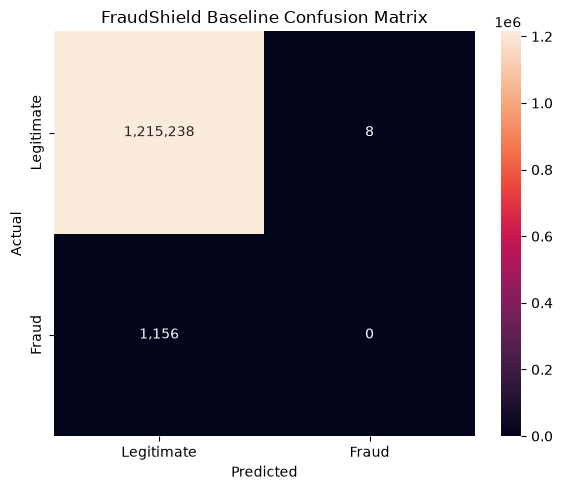

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt=",d",
    xticklabels=["Legitimate", "Fraud"],
    yticklabels=["Legitimate", "Fraud"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("FraudShield Baseline Confusion Matrix")
plt.tight_layout()
plt.show()

In [17]:
probability_summary = pd.DataFrame({
    "probability": y_validation_prob,
    "actual": y_validation_model.to_numpy()
})

probability_summary.groupby("actual")["probability"].describe()

,count,mean,std,min,25%,50%,75%,max
actual,,,,,,,,
0,1215246.0,0.000965,0.003464,0.000005,0.000043,0.000166,0.000920,0.918399
1,1156.0,0.012325,0.020276,0.000096,0.001149,0.004073,0.014324,0.208913


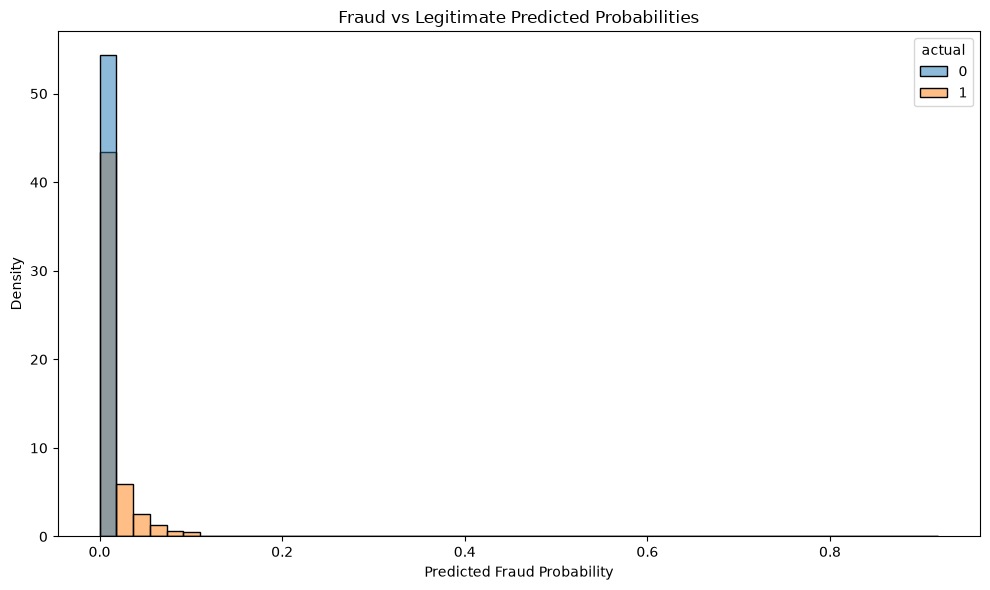

In [18]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=probability_summary,
    x="probability",
    hue="actual",
    bins=50,
    stat="density",
    common_norm=False
)

plt.xlabel("Predicted Fraud Probability")
plt.ylabel("Density")
plt.title("Fraud vs Legitimate Predicted Probabilities")
plt.tight_layout()
plt.show()

In [19]:
baseline_results = {
    "model": "Logistic Regression",
    "class_weight": None,
    "threshold": 0.50,
    "roc_auc": roc_auc_score(
        y_validation_model,
        y_validation_prob
    ),
    "pr_auc": average_precision_score(
        y_validation_model,
        y_validation_prob
    )
}

baseline_results

{'model': 'Logistic Regression',
 'class_weight': None,
 'threshold': 0.5,
 'roc_auc': 0.8759792533668279,
 'pr_auc': 0.03519252620307748}

Class-weighted Logistic Regression

In [20]:
weighted_model = Pipeline([
    (
        "scaler",
        StandardScaler()
    ),
    (
        "classifier",
        LogisticRegression(
            class_weight="balanced",
            max_iter=100,
            random_state=42
        )
    )
])

weighted_model.fit(
    X_train_model,
    y_train_model
)

print("Class-weighted model trained successfully.")

Class-weighted model trained successfully.


In [21]:
y_weighted_pred = weighted_model.predict(
    X_validation_model
)

y_weighted_prob = weighted_model.predict_proba(
    X_validation_model
)[:, 1]

In [22]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)

weighted_cm = confusion_matrix(
    y_validation_model,
    y_weighted_pred
)

print("Classification Report:\n")
print(
    classification_report(
        y_validation_model,
        y_weighted_pred,
        digits=4,
        zero_division=0
    )
)

print("\nConfusion Matrix:\n")
print(weighted_cm)

print("\nROC-AUC:")
print(
    roc_auc_score(
        y_validation_model,
        y_weighted_prob
    )
)

print("\nPR-AUC:")
print(
    average_precision_score(
        y_validation_model,
        y_weighted_prob
    )
)

Classification Report:

              precision    recall  f1-score   support

           0     0.9998    0.7761    0.8739   1215246
           1     0.0037    0.8763    0.0074      1156

    accuracy                         0.7762   1216402
   macro avg     0.5018    0.8262    0.4406   1216402
weighted avg     0.9989    0.7762    0.8730   1216402


Confusion Matrix:

[[943137 272109]
 [   143   1013]]

ROC-AUC:
0.9156012616056712

PR-AUC:
0.013603406251351887


Threshold Optimization

In [23]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [
    0.50,
    0.30,
    0.20,
    0.10,
    0.05,
    0.02,
    0.01,
    0.005,
    0.001
]

threshold_results = []

for threshold in thresholds:
    predictions = (
        y_weighted_prob >= threshold
    ).astype(int)

    threshold_results.append({
        "threshold": threshold,
        "precision": precision_score(
            y_validation_model,
            predictions,
            zero_division=0
        ),
        "recall": recall_score(
            y_validation_model,
            predictions,
            zero_division=0
        ),
        "f1": f1_score(
            y_validation_model,
            predictions,
            zero_division=0
        )
    })

threshold_results = pd.DataFrame(threshold_results)

threshold_results

,threshold,precision,recall,f1
0,0.500,0.003709,0.876298,0.007387
1,0.300,0.002188,0.987024,0.004367
2,0.200,0.002179,1.000000,0.004349
3,0.100,0.002179,1.000000,0.004349
4,0.050,0.002179,1.000000,0.004349
5,0.020,0.002179,1.000000,0.004349
6,0.010,0.002179,1.000000,0.004349
7,0.005,0.002179,1.000000,0.004349
8,0.001,0.002179,1.000000,0.004349


In [24]:
best_threshold_row = threshold_results.loc[
    threshold_results["f1"].idxmax()
]

print("Best threshold based on F1:")
print(best_threshold_row)

Best threshold based on F1:
threshold    0.500000
precision    0.003709
recall       0.876298
f1           0.007387
Name: 0, dtype: float64


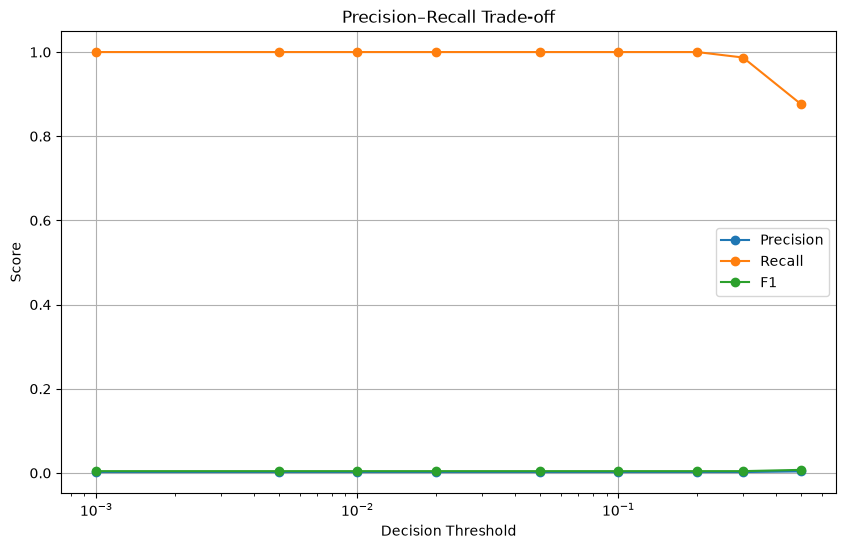

In [25]:
plt.figure(figsize=(10, 6))

plt.plot(
    threshold_results["threshold"],
    threshold_results["precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_results["threshold"],
    threshold_results["recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_results["threshold"],
    threshold_results["f1"],
    marker="o",
    label="F1"
)

plt.xscale("log")
plt.xlabel("Decision Threshold")
plt.ylabel("Score")
plt.title("Precision–Recall Trade-off")
plt.legend()
plt.grid(True)
plt.show()